# Week 1 Lab: PyTorch Foundations, Backpropagation, CNNs, and RNNs

This CPU-friendly notebook is the practical companion to Week 1 of **Deep Learning in 100 Hours**. It uses only generated data, so it does not download datasets or pretrained models.

## Before you run it

From the repository root, create the environment with **conda env create -f environment.yml**, activate it with **conda activate dl100h**, and start Jupyter with **jupyter lab**. Run the notebook from top to bottom once before changing any cells.

| Day | Main idea | Evidence to keep |
|---|---|---|
| 1 | Tensor shapes, broadcasting, autograd | Manual and autograd gradients agree |
| 2 | MLP, cross-entropy, backpropagation | Matrix BP and finite differences agree |
| 3 | DataLoader, train/validation, optimizers | A reproducible learning curve |
| 4 | Convolution and spatial features | A tiny CNN overfits synthetic images |
| 5 | GRU, gradient clipping, checkpoints | Sequence model and checkpoint round trip work |

**Working rule:** predict the shape or outcome before running a cell. The notebook is deliberately small enough to reset and rerun often.

In [1]:
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, random_split

from dl100h.cnn import SmallCNN, make_stripe_images
from dl100h.data import TwoMoonsLike
from dl100h.recurrent import GRUClassifier, make_sequence_task
from dl100h.training import classification_epoch, load_checkpoint, save_checkpoint
from dl100h.utils import count_parameters, seed_everything

seed_everything(42)
device = torch.device('cpu')
print({'torch': torch.__version__, 'device': str(device), 'cuda_available': torch.cuda.is_available()})

{'torch': '2.5.1', 'device': 'cpu', 'cuda_available': False}


# Day 1 — Tensors, shapes, broadcasting, and autograd

Treat every axis as having a meaning. In the linear model below, $X\in\mathbb{R}^{B\times C}$, $w\in\mathbb{R}^{C}$, and $\hat{y}=Xw\in\mathbb{R}^{B}$. For mean squared error,

$$L=\frac{1}{B}\lVert Xw-y\rVert_2^2,\qquad \frac{\partial L}{\partial w}=\frac{2}{B}X^\top(Xw-y).$$

PyTorch records operations from leaf tensors with gradients enabled. Calling backward on a scalar applies the chain rule and **accumulates** values in the grad fields.

In [2]:
torch.manual_seed(1)
batch_size, n_features = 4, 3
x = torch.randn(batch_size, n_features)
target = torch.randn(batch_size)
weight = torch.randn(n_features, requires_grad=True)

prediction = x @ weight
loss = (prediction - target).square().mean()
manual_gradient = (2 / batch_size) * x.T @ (prediction.detach() - target)
loss.backward()

torch.testing.assert_close(weight.grad, manual_gradient)
{
    'x_shape': tuple(x.shape),
    'prediction_shape': tuple(prediction.shape),
    'loss': loss.item(),
    'maximum_gradient_error': (weight.grad - manual_gradient).abs().max().item(),
}

{'x_shape': (4, 3),
 'prediction_shape': (4,),
 'loss': 1.1219843626022339,
 'maximum_gradient_error': 0.0}

In [3]:
# A legal broadcast can still be a semantic bug.
correct_residual = prediction.detach() - target
column_prediction = prediction.detach().unsqueeze(1)
incorrect_residual = column_prediction - target

assert correct_residual.shape == (batch_size,)
assert incorrect_residual.shape == (batch_size, batch_size)
{'correct': tuple(correct_residual.shape), 'silent_broadcast_bug': tuple(incorrect_residual.shape)}

{'correct': (4,), 'silent_broadcast_bug': (4, 4)}

## Day 1 practice and acceptance

1. Change mean to sum in the loss. Predict the gradient scaling factor before running.
2. Call backward twice without clearing weight.grad, then explain the result.
3. Replace view with reshape after creating a non-contiguous transpose.

**Accept the day when:** you can annotate every tensor shape, reproduce the manual gradient, and explain why a result with shape $(B,B)$ is wrong even though PyTorch accepts it.

# Day 2 — MLPs, cross-entropy, and backpropagation

For a two-layer MLP, define $Z_1=XW_1+b_1$, $A_1=\tanh(Z_1)$, and $Z_2=A_1W_2+b_2$. With mean cross-entropy and softmax probabilities $P$,

$$\Delta_2=\frac{P-Y}{B},\quad \nabla W_2=A_1^\top\Delta_2,$$

$$\Delta_1=(\Delta_2W_2^\top)\odot(1-A_1^2),\quad \nabla W_1=X^\top\Delta_1.$$

The next cell compares these equations with autograd and then checks one coordinate with a central finite difference.

In [4]:
torch.manual_seed(2)
B, D, H, K = 5, 2, 4, 2
features = torch.randn(B, D, dtype=torch.float64)
labels = torch.tensor([0, 1, 1, 0, 1])
W1 = torch.randn(D, H, dtype=torch.float64, requires_grad=True)
b1 = torch.zeros(H, dtype=torch.float64, requires_grad=True)
W2 = torch.randn(H, K, dtype=torch.float64, requires_grad=True)
b2 = torch.zeros(K, dtype=torch.float64, requires_grad=True)

z1 = features @ W1 + b1
a1 = torch.tanh(z1)
logits = a1 @ W2 + b2
mlp_loss = F.cross_entropy(logits, labels)
mlp_loss.backward()

with torch.no_grad():
    probabilities = logits.softmax(dim=-1)
    one_hot = F.one_hot(labels, num_classes=K).to(torch.float64)
    delta2 = (probabilities - one_hot) / B
    manual_dW2 = a1.T @ delta2
    delta1 = (delta2 @ W2.T) * (1 - a1.square())
    manual_dW1 = features.T @ delta1

torch.testing.assert_close(W2.grad, manual_dW2)
torch.testing.assert_close(W1.grad, manual_dW1)
{
    'loss': mlp_loss.item(),
    'dW1_max_error': (W1.grad - manual_dW1).abs().max().item(),
    'dW2_max_error': (W2.grad - manual_dW2).abs().max().item(),
}

{'loss': 0.7465358055733542,
 'dW1_max_error': 5.551115123125783e-17,
 'dW2_max_error': 5.551115123125783e-17}

In [5]:
def loss_with_first_layer(first_layer: torch.Tensor) -> torch.Tensor:
    hidden = torch.tanh(features @ first_layer + b1.detach())
    return F.cross_entropy(hidden @ W2.detach() + b2.detach(), labels)

index = (0, 0)
epsilon = 1e-5
plus = W1.detach().clone()
minus = W1.detach().clone()
plus[index] += epsilon
minus[index] -= epsilon
finite_difference = (loss_with_first_layer(plus) - loss_with_first_layer(minus)) / (2 * epsilon)
autograd_value = W1.grad[index]

torch.testing.assert_close(finite_difference, autograd_value, rtol=1e-5, atol=1e-7)
{'finite_difference': finite_difference.item(), 'autograd': autograd_value.item()}

{'finite_difference': -0.0516269105133027, 'autograd': -0.05162691051774156}

## Day 2 practice and acceptance

1. Derive and verify the gradients for both bias vectors.
2. Replace tanh with ReLU and update the derivative in the manual backward pass.
3. Try epsilon values from $10^{-1}$ to $10^{-8}$ and explain truncation versus floating-point error.

**Accept the day when:** all parameter-gradient shapes are correct, manual BP agrees with autograd, and at least one finite-difference check agrees within a stated tolerance.

# Day 3 — A complete training and validation pipeline

A trustworthy loop separates training from evaluation. Training uses train mode, gradients, zero_grad, backward, and an optimizer step. Validation uses eval mode and inference mode, and it never updates parameters. Keep the split and shuffling reproducible with explicit random generators.

In [6]:
seed_everything(3)
dataset = TwoMoonsLike(512, noise=0.10, seed=3)
split_generator = torch.Generator().manual_seed(3)
shuffle_generator = torch.Generator().manual_seed(30)
train_set, valid_set = random_split(dataset, [400, 112], generator=split_generator)
train_loader = DataLoader(train_set, batch_size=32, shuffle=True, generator=shuffle_generator)
valid_loader = DataLoader(valid_set, batch_size=64, shuffle=False)

classifier = nn.Sequential(nn.Linear(2, 32), nn.Tanh(), nn.Linear(32, 2)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(classifier.parameters(), lr=0.03, weight_decay=1e-4)
print({'train_examples': len(train_set), 'valid_examples': len(valid_set), 'parameters': count_parameters(classifier)})

{'train_examples': 400, 'valid_examples': 112, 'parameters': 162}


In [7]:
history = []
for epoch in range(20):
    train_result = classification_epoch(classifier, train_loader, loss_fn, device, optimizer)
    valid_result = classification_epoch(classifier, valid_loader, loss_fn, device)
    history.append({
        'epoch': epoch + 1,
        'train_loss': train_result.loss,
        'train_accuracy': train_result.accuracy,
        'valid_loss': valid_result.loss,
        'valid_accuracy': valid_result.accuracy,
    })

assert history[-1]['valid_accuracy'] >= 0.80
history[-1]

{'epoch': 20,
 'train_loss': 0.024116963818669318,
 'train_accuracy': 0.9925,
 'valid_loss': 0.024878765057240213,
 'valid_accuracy': 0.9910714285714286}

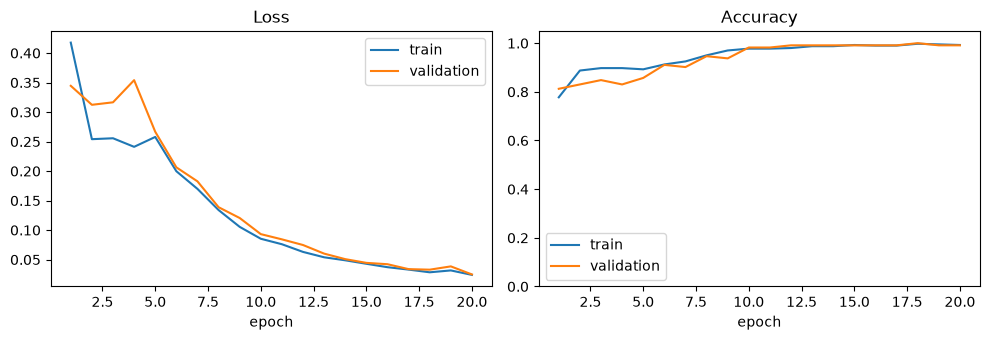

In [8]:
epochs = [row['epoch'] for row in history]
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(epochs, [row['train_loss'] for row in history], label='train')
axes[0].plot(epochs, [row['valid_loss'] for row in history], label='validation')
axes[0].set(title='Loss', xlabel='epoch')
axes[0].legend()
axes[1].plot(epochs, [row['train_accuracy'] for row in history], label='train')
axes[1].plot(epochs, [row['valid_accuracy'] for row in history], label='validation')
axes[1].set(title='Accuracy', xlabel='epoch', ylim=(0.0, 1.05))
axes[1].legend()
figure.tight_layout()
plt.show()

## Day 3 practice and acceptance

1. Compare AdamW with SGD plus momentum while keeping the split, model initialization, and epoch budget fixed.
2. Remove zero_grad and explain the learning curve.
3. Add a learning-rate scheduler and record the learning rate beside each epoch.
4. Increase model width until the train/validation gap becomes visible.

**Accept the day when:** you can explain every line of the loop, reproduce the run from a seed, and distinguish optimization failure from overfitting.

# Day 4 — CNNs and spatial inductive bias

A convolution reuses local filters across image positions. For an input $(B,C,H,W)$, trace the channel and spatial dimensions after every convolution and pooling operation. The synthetic task below classifies vertical versus horizontal stripes and is designed for a fast overfitting check.

In [9]:
seed_everything(4)
images, image_labels = make_stripe_images(n=16, seed=4)
cnn = SmallCNN().to(device)
cnn_optimizer = torch.optim.Adam(cnn.parameters(), lr=0.02)

with torch.inference_mode():
    feature_shape = tuple(cnn.forward_features(images.to(device)).shape)

cnn_losses = []
for step in range(80):
    logits = cnn(images.to(device))
    cnn_loss = F.cross_entropy(logits, image_labels.to(device))
    cnn_optimizer.zero_grad(set_to_none=True)
    cnn_loss.backward()
    cnn_optimizer.step()
    cnn_losses.append(cnn_loss.item())

cnn.eval()
with torch.inference_mode():
    cnn_predictions = cnn(images.to(device)).argmax(dim=-1).cpu()
cnn_accuracy = (cnn_predictions == image_labels).float().mean().item()
assert cnn_accuracy >= 0.95
{
    'input_shape': tuple(images.shape),
    'feature_shape': feature_shape,
    'parameters': count_parameters(cnn),
    'final_loss': cnn_losses[-1],
    'accuracy': cnn_accuracy,
}

{'input_shape': (16, 1, 16, 16),
 'feature_shape': (16, 16, 4, 4),
 'parameters': 1762,
 'final_loss': 0.0,
 'accuracy': 1.0}

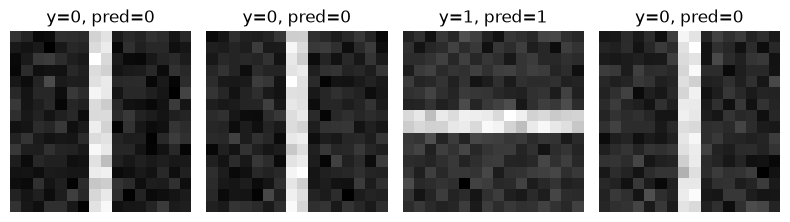

In [10]:
figure, axes = plt.subplots(1, 4, figsize=(8, 2.2))
for axis, image, label, prediction in zip(axes, images[:4], image_labels[:4], cnn_predictions[:4]):
    axis.imshow(image.squeeze(0), cmap='gray')
    axis.set_title(f'y={label.item()}, pred={prediction.item()}')
    axis.axis('off')
figure.tight_layout()
plt.show()

## Day 4 practice and acceptance

1. Compute the receptive field and output shape of each layer by hand.
2. Replace the second convolution with a linear layer over pixels and compare parameter counts.
3. Increase the noise and plot accuracy against noise level.

**Accept the day when:** you can trace $(B,C,H,W)$ through the network, explain weight sharing, and overfit the tiny batch without external data.

# Day 5 — GRUs, sequence state, gradient clipping, and checkpoints

A recurrent model reuses the same transition across time. A GRU controls how much previous state to retain or replace. The lightweight task below classifies sequences according to the sign of their first feature. Gradient clipping limits the global gradient norm before an optimizer step.

In [11]:
seed_everything(5)
sequences, sequence_labels = make_sequence_task(n=32, sequence_length=12, seed=5)
gru = GRUClassifier(input_size=3, hidden_size=12, n_classes=2).to(device)
gru_optimizer = torch.optim.Adam(gru.parameters(), lr=0.02)

for step in range(60):
    sequence_logits = gru(sequences.to(device))
    gru_loss = F.cross_entropy(sequence_logits, sequence_labels.to(device))
    gru_optimizer.zero_grad(set_to_none=True)
    gru_loss.backward()
    unclipped_norm = torch.nn.utils.clip_grad_norm_(gru.parameters(), max_norm=1.0)
    gru_optimizer.step()

gru.eval()
with torch.inference_mode():
    sequence_predictions = gru(sequences.to(device)).argmax(dim=-1).cpu()
gru_accuracy = (sequence_predictions == sequence_labels).float().mean().item()
assert gru_accuracy >= 0.95
{
    'sequence_shape': tuple(sequences.shape),
    'logit_shape': tuple(sequence_logits.shape),
    'parameters': count_parameters(gru),
    'last_pre_clip_norm': float(unclipped_norm),
    'accuracy': gru_accuracy,
}

{'sequence_shape': (32, 12, 3),
 'logit_shape': (32, 2),
 'parameters': 638,
 'last_pre_clip_norm': 0.0006307999137789011,
 'accuracy': 1.0}

In [12]:
with tempfile.TemporaryDirectory() as temporary_directory:
    checkpoint_path = Path(temporary_directory) / 'week01_gru.pt'
    with torch.inference_mode():
        expected_logits = gru(sequences[:4].to(device)).cpu()
    save_checkpoint(
        checkpoint_path,
        gru,
        gru_optimizer,
        epoch=60,
        metadata={'seed': 5, 'task': 'synthetic-sequence-classification'},
    )

    restored_gru = GRUClassifier(input_size=3, hidden_size=12, n_classes=2).to(device)
    restored_optimizer = torch.optim.Adam(restored_gru.parameters(), lr=0.02)
    checkpoint_state = load_checkpoint(
        checkpoint_path,
        restored_gru,
        restored_optimizer,
        map_location=device,
    )
    restored_gru.eval()
    with torch.inference_mode():
        restored_logits = restored_gru(sequences[:4].to(device)).cpu()
    torch.testing.assert_close(restored_logits, expected_logits)

{
    'restored_epoch': checkpoint_state['epoch'],
    'metadata': checkpoint_state['metadata'],
    'prediction_round_trip': True,
    'optimizer_state_restored': bool(restored_optimizer.state_dict()['state']),
}

{'restored_epoch': 60,
 'metadata': {'seed': 5, 'task': 'synthetic-sequence-classification'},
 'prediction_round_trip': True,
 'optimizer_state_restored': True}

## Day 5 practice and acceptance

1. Pass explicit sequence lengths to the GRU and explain why padded time steps should not change the final representation.
2. Log gradient norms before clipping and compare thresholds 0.1, 1.0, and 10.0.
3. Resume training from a checkpoint and verify that the loss continues from the restored state.

**Accept the day when:** you can identify batch, time, feature, and hidden axes; explain the role of recurrent state; and prove that model predictions survive a checkpoint round trip.

# Week 1 acceptance checklist

- [ ] I can derive a linear-regression gradient and a two-layer MLP backward pass.
- [ ] I can detect a silent broadcasting error from tensor semantics, not only syntax.
- [ ] I can write separate training and validation loops and justify train/eval modes.
- [ ] I can explain SGD, momentum, AdamW, learning rate, and weight decay at a practical level.
- [ ] I can trace CNN and GRU tensor shapes.
- [ ] I can overfit one tiny image batch and one tiny sequence batch.
- [ ] I can save and restore model plus optimizer state.

Record your answers, modifications, plots, and failed experiments in the experiment-log template. Continue to Week 2 only after you can reproduce the notebook from a fresh kernel.